# PS- 2C: CNN for Sign Language MNIST Classification

Open this notebook with `PS- 2C` as the working folder and run the cells from top to bottom using a Python 3 kernel with TensorFlow, pandas, matplotlib, and scikit-learn installed. Both CSV files are loaded from this folder only.

Each image has 784 pixels, reshaped to 28 x 28 with one grayscale channel. The 24 labels are 0-8 and 10-24, so `LabelEncoder` converts them to consecutive class IDs using the training labels.


In [1]:
# Import all necessary packages first
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam


In [2]:
# a. Load and preprocess the image data
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Scale pixels to 0-1 and reshape to (images, height, width, channels).
x_train = train.drop("label", axis=1).values.astype("float32") / 255.0
x_test = test.drop("label", axis=1).values.astype("float32") / 255.0
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Fit the label mapping on training data and reuse it for testing.
encoder = LabelEncoder()
y_train = encoder.fit_transform(train["label"])
y_test = encoder.transform(test["label"])


In [ ]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = encoder.inverse_transform(y_train[:10])
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [3]:
# b. Define the model's architecture
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(len(encoder.classes_), activation="softmax")
])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         102,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 122,840 (479.84 KB)

 Trainable params: 122,840 (479.84 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# c. Train the model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=10, batch_size=64,
                    validation_split=0.1, verbose=2)


Epoch 1/10
387/387 - 28s - 72ms/step - accuracy: 0.6106 - loss: 1.3382 - val_accuracy: 0.9017 - val_loss: 0.3708
Epoch 2/10
387/387 - 12s - 31ms/step - accuracy: 0.9526 - loss: 0.1922 - val_accuracy: 0.9880 - val_loss: 0.0751
Epoch 3/10
387/387 - 11s - 29ms/step - accuracy: 0.9962 - loss: 0.0414 - val_accuracy: 1.0000 - val_loss: 0.0216
Epoch 4/10
387/387 - 11s - 29ms/step - accuracy: 0.9998 - loss: 0.0123 - val_accuracy: 0.9996 - val_loss: 0.0073
Epoch 5/10
387/387 - 12s - 31ms/step - accuracy: 0.9999 - loss: 0.0058 - val_accuracy: 0.9993 - val_loss: 0.0096
Epoch 6/10
387/387 - 13s - 34ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 0.0023
Epoch 7/10
387/387 - 21s - 53ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 8/10
387/387 - 17s - 45ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 0.0010
Epoch 9/10
387/387 - 9s - 24ms/step - accuracy: 0.9908 - loss: 0.0294 - val_accuracy: 1.0000 - v

Test loss: 0.5027
Test accuracy: 88.78%


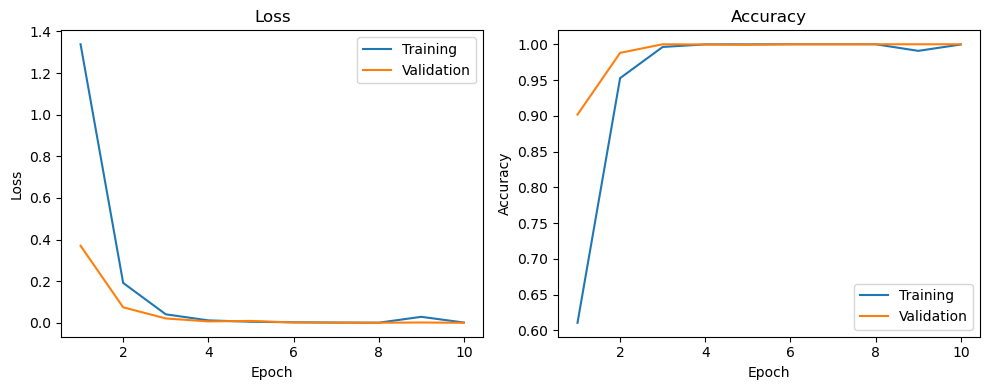

In [5]:
# d. Estimate the model's performance on the testing data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

# Compare training and validation performance across epochs.
epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"], label="Training")
plt.plot(epochs, history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"], label="Training")
plt.plot(epochs, history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()
